# 🚀 Canlı Sinyallerden Kâr/Zarar (PnL) Simülasyonu

Bu notebook, `logs/multi_signals_*.csv` dosyasındaki AL-SAT-BEKLE sinyallerini kronolojik olarak okur. İşlemleri eşleştirerek Entry (Giriş) ve Exit (Çıkış) fiyatlarını bulur ve **komisyonlar düşüldükten sonra** hangi altcoinde ne kadar kâr/zarar edildiğini hesaplar.

In [169]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import glob
import os

sns.set_theme(style="darkgrid")
plt.rcParams['figure.figsize'] = (12, 6)

### 1. Canlı Sinyal Verisini Yükleme

In [170]:
# En guncel multi_signals dosyasini otomatik bul
csv_files = glob.glob('../logs/multi_signals_*.csv')

if csv_files:
    CSV_FILE = max(csv_files, key=os.path.getctime)
    df = pd.read_csv(CSV_FILE)
    df['Zaman'] = pd.to_datetime(df['Zaman'])
    df = df.sort_values(by=['Sembol', 'Zaman']) # Sembole ve zamana gore sirala
    print(f"✅ {CSV_FILE} yuklendi! Toplam sinyal: {len(df)}")
else:
    print("❌ ../logs/ dizininde multi_signals CSV dosyasi bulunamadi.")
    df = pd.DataFrame()

✅ ../logs\multi_signals_2026-10-01.csv yuklendi! Toplam sinyal: 316


### 2. Sinyalleri Gerçek İşlemlere (Trade) Dönüştürme Motoru

In [171]:
trades = []
COMMISSION_ROUND_TRIP = 0.00032 # Limit(Maker) komisyonu (Giris %0.016 + Cikis %0.016)

if not df.empty:
    # Her bir Altcoin icin ayri ayri simule et
    for symbol, group in df.groupby('Sembol'):
        position = 0 # 1 = LONG, -1 = SHORT, 0 = NAKIT
        entry_price = 0.0
        entry_time = None
        
        for idx, row in group.iterrows():
            sig = row['Sinyal_Yonu']
            price = float(row['Fiyat'])
            time = row['Zaman']
            
            if position == 0:
                if 'AL (LONG)' in sig:
                    position = 1
                    entry_price = price
                    entry_time = time
                elif 'SAT (SHORT)' in sig:
                    position = -1
                    entry_price = price
                    entry_time = time
            
            elif position == 1:
                if 'BEKLE' in sig or 'SAT' in sig:
                    # LONG Cikis
                    brut_pnl_pct = (price - entry_price) / entry_price
                    net_pnl_pct = brut_pnl_pct - COMMISSION_ROUND_TRIP
                    trades.append({"Sembol": symbol, "Yon": "LONG", "Giris_Zaman": entry_time, "Cikis_Zaman": time, 
                                   "Entry_Fiyat": entry_price, "Exit_Fiyat": price, "Net_PnL_%": net_pnl_pct * 100})
                    
                    if 'SAT' in sig:
                        position = -1; entry_price = price; entry_time = time
                    else:
                        position = 0
                        
            elif position == -1:
                if 'BEKLE' in sig or 'AL' in sig:
                    # SHORT Cikis
                    brut_pnl_pct = (entry_price - price) / entry_price
                    net_pnl_pct = brut_pnl_pct - COMMISSION_ROUND_TRIP
                    trades.append({"Sembol": symbol, "Yon": "SHORT", "Giris_Zaman": entry_time, "Cikis_Zaman": time, 
                                   "Entry_Fiyat": entry_price, "Exit_Fiyat": price, "Net_PnL_%": net_pnl_pct * 100})
                    
                    if 'AL' in sig:
                        position = 1; entry_price = price; entry_time = time
                    else:
                        position = 0

    df_trades = pd.DataFrame(trades)
    if not df_trades.empty:
        print(f"✅ {len(df_trades)} adet kapanmis islem olusturuldu.")
        display(df_trades.head())
    else:
        print("Henuz kapanmis (Giris ve Cikisi tamamlanmis) bir islem yok.")

✅ 152 adet kapanmis islem olusturuldu.


,Sembol,Yon,Giris_Zaman,Cikis_Zaman,Entry_Fiyat,Exit_Fiyat,Net_PnL_%
0,AAVEUSDT,SHORT,2026-10-01 18:58:28,2026-10-01 19:16:41,168.18000,166.71500,0.839090
1,AAVEUSDT,SHORT,2026-10-01 21:19:06,2026-10-01 21:37:59,168.64000,168.98500,-0.236578
2,AAVEUSDT,LONG,2026-10-01 22:41:19,2026-10-01 23:05:44,167.83500,170.08500,1.308602
3,APTUSDT,LONG,2026-10-01 18:36:23,2026-10-01 18:39:29,0.76475,0.76765,0.347209
4,APTUSDT,LONG,2026-10-01 18:40:37,2026-10-01 21:12:42,0.76685,0.77625,1.193794


### 3. Altcoinlere Göre Toplam PnL (Kâr/Zarar) Analizi

C:\Users\ulker\AppData\Local\Temp\ipykernel_5172\1636945191.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=pnl_by_symbol, x='Sembol', y='Net_PnL_%', palette=colors)


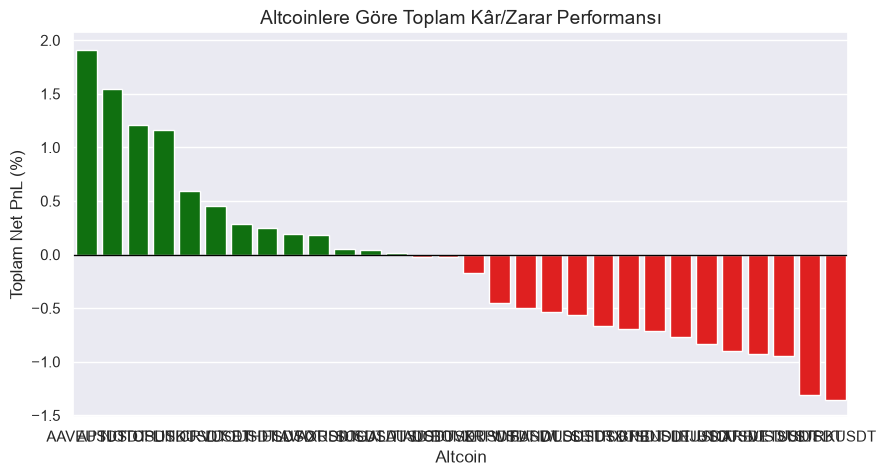

,Sembol,Net_PnL_%
0,AAVEUSDT,1.911115
1,APTUSDT,1.541003
15,NOTUSDT,1.205113
16,OPUSDT,1.158020
14,LINKUSDT,0.595200
7,CRVUSDT,0.456527
13,LDOUSDT,0.288110
9,ETHUSDT,0.247487
10,FILUSDT,0.192207
3,AVAXUSDT,0.179246


In [172]:
if 'df_trades' in locals() and not df_trades.empty:
    pnl_by_symbol = df_trades.groupby('Sembol')['Net_PnL_%'].sum().reset_index()
    pnl_by_symbol = pnl_by_symbol.sort_values(by='Net_PnL_%', ascending=False)
    
    plt.figure(figsize=(10, 5))
    colors = ['green' if x > 0 else 'red' for x in pnl_by_symbol['Net_PnL_%']]
    sns.barplot(data=pnl_by_symbol, x='Sembol', y='Net_PnL_%', palette=colors)
    
    plt.title('Altcoinlere Göre Toplam Kâr/Zarar Performansı', fontsize=14)
    plt.xlabel('Altcoin')
    plt.ylabel('Toplam Net PnL (%)')
    plt.axhline(0, color='black', linestyle='-', linewidth=1)
    plt.show()
    
    display(pnl_by_symbol)

### 4. Başarı Oranı (Win Rate) ve Risk Tablosu

In [173]:
if 'df_trades' in locals() and not df_trades.empty:
    win_rate = (len(df_trades[df_trades['Net_PnL_%'] > 0]) / len(df_trades)) * 100
    avg_win = df_trades[df_trades['Net_PnL_%'] > 0]['Net_PnL_%'].mean()
    avg_loss = df_trades[df_trades['Net_PnL_%'] <= 0]['Net_PnL_%'].mean()
    
    print("="*40)
    print(f"📊 GENEL STRATEJİ PERFORMANSI")
    print("="*40)
    print(f"Toplam Kapanmış İşlem : {len(df_trades)}")
    print(f"Genel Başarı Oranı    : %{win_rate:.2f}")
    print(f"Ortalama Kâr (Win)    : %{avg_win:.3f}")
    print(f"Ortalama Zarar (Loss) : %{avg_loss:.3f}")
    print(f"Toplam Net Getiri     : %{df_trades['Net_PnL_%'].sum():.3f}")
    print("="*40)

📊 GENEL STRATEJİ PERFORMANSI
Toplam Kapanmış İşlem : 152
Genel Başarı Oranı    : %37.50
Ortalama Kâr (Win)    : %0.311
Ortalama Zarar (Loss) : %-0.223
Toplam Net Getiri     : %-3.483


In [174]:
df_trades[df_trades['Sembol'] == 'APTUSDT'].sort_values(by='Giris_Zaman', ascending=False).head(10)

,Sembol,Yon,Giris_Zaman,Cikis_Zaman,Entry_Fiyat,Exit_Fiyat,Net_PnL_%
4,APTUSDT,LONG,2026-10-01 18:40:37,2026-10-01 21:12:42,0.76685,0.77625,1.193794
3,APTUSDT,LONG,2026-10-01 18:36:23,2026-10-01 18:39:29,0.76475,0.76765,0.347209


### 5. Sembol (Tahta) Bazlı Detaylı Karne (Tahta Seçimi İçin)

Aşağıdaki tablo, stratejinin hangi coinlerde gerçekten çalıştığını, hangilerinde ise manipülasyona kurban gittiğini tespit etmemizi sağlar. Tablo **Net PnL**'e göre sıralanmıştır.

In [175]:
if 'df_trades' in locals() and not df_trades.empty:
    stats = []
    for sym, group in df_trades.groupby('Sembol'):
        toplam_islem = len(group)
        kazananlar = group[group['Net_PnL_%'] > 0]
        kaybedenler = group[group['Net_PnL_%'] <= 0]
        
        win_rate = (len(kazananlar) / toplam_islem) * 100
        net_pnl = group['Net_PnL_%'].sum()
        avg_win = kazananlar['Net_PnL_%'].mean() if not kazananlar.empty else 0
        avg_loss = kaybedenler['Net_PnL_%'].mean() if not kaybedenler.empty else 0
        
        stats.append({
            'Sembol': sym,
            'İşlem Sayısı': toplam_islem,
            'Win Rate (%)': win_rate,
            'Net PnL (%)': net_pnl,
            'Ort. Kâr (%)': avg_win,
            'Ort. Zarar (%)': avg_loss
        })
        
    df_stats = pd.DataFrame(stats)
    df_stats = df_stats.sort_values(by='Net PnL (%)', ascending=False).reset_index(drop=True)
    
    # Gorsel olarak zenginlestirilmis tablo
    styled_table = (df_stats.style
                    .background_gradient(cmap='RdYlGn', subset=['Net PnL (%)', 'Win Rate (%)'])
                    .format({'Win Rate (%)': '{:.1f}', 'Net PnL (%)': '{:.3f}', 
                             'Ort. Kâr (%)': '{:.3f}', 'Ort. Zarar (%)': '{:.3f}'}))
    
    display(styled_table)
else:
    print("Analiz edilecek kapalı işlem bulunamadı.")

,Sembol,İşlem Sayısı,Win Rate (%),Net PnL (%),Ort. Kâr (%),Ort. Zarar (%)
0,AAVEUSDT,3,66.7,1.911,1.074,-0.237
1,APTUSDT,2,100.0,1.541,0.771,0.000
2,NOTUSDT,1,100.0,1.205,1.205,0.000
3,OPUSDT,2,50.0,1.158,1.504,-0.346
4,LINKUSDT,1,100.0,0.595,0.595,0.000
5,CRVUSDT,4,50.0,0.457,0.469,-0.241
6,LDOUSDT,1,100.0,0.288,0.288,0.000
7,ETHUSDT,11,45.5,0.247,0.127,-0.065
8,FILUSDT,3,33.3,0.192,0.720,-0.264
9,AVAXUSDT,7,57.1,0.179,0.605,-0.747
